In [1]:
import cv2

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [2]:
image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))

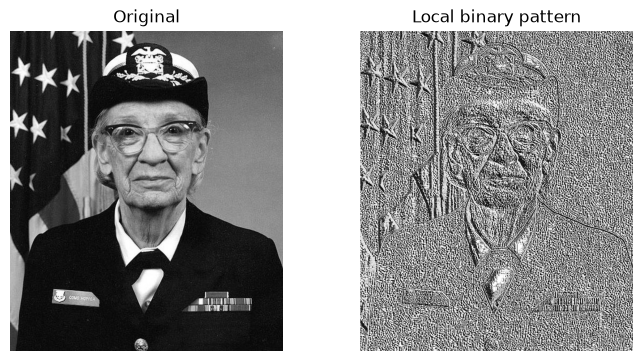

In [3]:
# Question 1
height, width = image.shape
padded = np.pad(image, 1, mode="edge")
offsets = [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (1, 0)]
lbp = np.zeros_like(image)

for bit, (row, col) in enumerate(offsets):
    neighbor = padded[row:row + height, col:col + width]
    lbp |= (neighbor >= image).astype(np.uint8) << bit

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), layout="constrained")
for ax, result, title in zip(axes, (image, lbp), ("Original", "Local binary pattern")):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

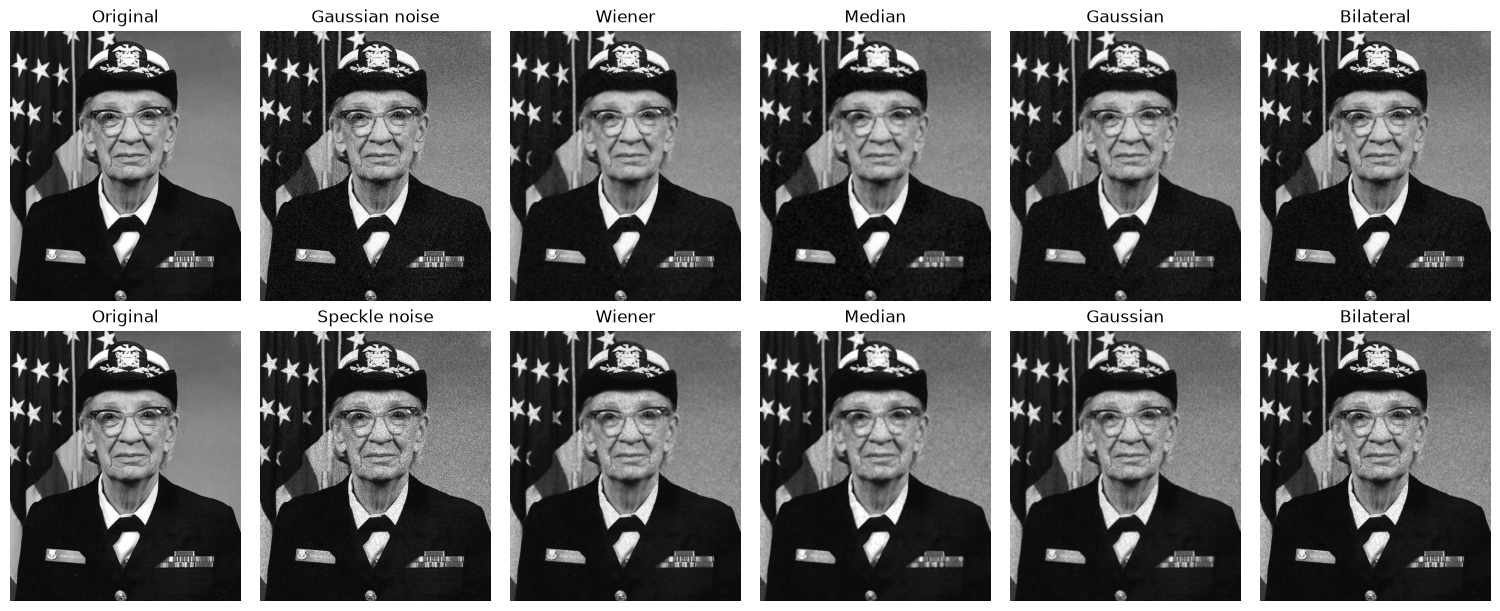

In [4]:
# Question 2
def wiener_filter(noisy, size):
    pixels = noisy.astype(np.float32)
    window = (size, size)
    mean = cv2.blur(pixels, window)
    variance = np.maximum(cv2.blur(pixels ** 2, window) - mean ** 2, 0)
    noise_variance = variance.mean()
    gain = np.maximum(variance - noise_variance, 0) / np.maximum(variance, 1e-6)
    return mean + gain * (pixels - mean)


size = 5
rng = np.random.default_rng(42)
gaussian_noise = image + rng.normal(0, 20, image.shape)
speckle_noise = image * (1 + rng.normal(0, 0.2, image.shape))
fig, axes = plt.subplots(2, 6, figsize=(15, 6), layout="constrained")

for row, noise, name in zip(axes, (gaussian_noise, speckle_noise), ("Gaussian", "Speckle")):
    noisy = np.rint(np.clip(noise, 0, 255)).astype(np.uint8)
    results = (
        image,
        noisy,
        wiener_filter(noisy, size),
        cv2.medianBlur(noisy, size),
        cv2.GaussianBlur(noisy, (size, size), 1),
        cv2.bilateralFilter(noisy, size, 40, 10),
    )
    titles = ("Original", f"{name} noise", "Wiener", "Median", "Gaussian", "Bilateral")
    for ax, result, title in zip(row, results, titles):
        ax.imshow(result, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
plt.show()